# Trotter circuits from Magritte: real AIM-chain export

`anderson_impurity.ipynb` builds `AndersonImpurity` Hamiltonians and their exact spectra in
Qaravan alone. This notebook closes the loop with the other side of Task 22
(`qaravan.interop.magritte`): it loads a *real* Magritte-compiled Trotter-circuit export for
the AIM chain geometry (3 baths, so 8 qubits), converts every gate through
`from_magritte_json`, and checks that the resulting circuits converge to the exact
propagator $e^{-iHT}$ of the *same* Hamiltonian built independently in Qaravan -- with the
expected first-/second-order Trotter scaling.

The export lives in `.dev/trotter_error_sweep_aim_chain_3bath/` (untracked scratch data,
dropped in by hand -- not part of the repo).

In [1]:
import json

import numpy as np
from scipy.linalg import expm

from qaravan.backends.statevector import Statevector, StatevectorSimulator
from qaravan.core.fermions import FermionicEncoding
from qaravan.core.hamiltonians import AndersonImpurity
from qaravan.interop.magritte import from_magritte_json
from qaravan.plot import set_style

import matplotlib.pyplot as plt

set_style()
np.set_printoptions(precision=4, suppress=True)

DATA_DIR = "../../.dev/trotter_error_sweep_aim_chain_3bath/trotter_error_sweep_aim_chain_3bath"

## 1. Load the export

`manifest.json` records the model parameters once (chain geometry, 3 baths) and a sweep over
`(n_steps, order)` points at fixed total time $T=1$; each point's own file holds **one Trotter
step's worth of gates** (`dt = T / n_steps`), not the whole repeated circuit -- the gate count
in every `order=1` file is 26 regardless of `n_steps`, and every `order=2` file is 48. To
reach the full evolution we apply that one-step circuit `n_steps` times.

In [2]:
manifest = json.load(open(f"{DATA_DIR}/manifest.json"))
model = manifest["model"]
T = manifest["total_time"]
print(f"topology={model['topology']!r}  T={T}")
model

topology='chain'  T=1.0


{'topology': 'chain',
 'eps_d': 0.1,
 'U': 4.0,
 'eps_chain': [0.5, -0.5, 0.2],
 't_chain': [0.3, 0.3],
 'V': 0.3}

## 2. The same Hamiltonian, built independently in Qaravan

`manifest['model']` is exactly `AndersonImpurity.chain`'s own keyword arguments. Building it
here -- with no reference to the exported gates -- gives an independent target to Trotterize
against. `mode_order` in every point file is the identity `[0, ..., 7]`, matching
`AndersonImpurity`'s canonical `spin*(num_bath+1)+site` labeling with no permutation needed.

In [ ]:
chain = AndersonImpurity.chain(
    eps_d=model["eps_d"],
    U=model["U"],
    eps_chain=model["eps_chain"],
    t_chain=model["t_chain"],
    V=model["V"],
)
encoding = FermionicEncoding("jordan_wigner", num_modes=chain.num_fermionic_modes)
ham = chain.encode(encoding)
H = ham.to_matrix()
num_qubits = chain.num_fermionic_modes
dim = 2**num_qubits
print(f"num_qubits={num_qubits}  dim={dim}  Hermitian: {np.allclose(H, H.conj().T)}")

In [4]:
U_exact = expm(-1j * H * T)
print("unitary:", np.allclose(U_exact.conj().T @ U_exact, np.eye(dim), atol=1e-8))

unitary: True


/Users/alam/code/qaravan-rewrite/.venv/lib/python3.13/site-packages/scipy/linalg/_matfuncs.py:394: RuntimeWarning: divide by zero encountered in matmul
  eAw = eAw @ eAw
/Users/alam/code/qaravan-rewrite/.venv/lib/python3.13/site-packages/scipy/linalg/_matfuncs.py:394: RuntimeWarning: overflow encountered in matmul
  eAw = eAw @ eAw
/Users/alam/code/qaravan-rewrite/.venv/lib/python3.13/site-packages/scipy/linalg/_matfuncs.py:394: RuntimeWarning: invalid value encountered in matmul
  eAw = eAw @ eAw
/var/folders/3y/dkx5cjxs3x5gtbx3dzjdhb980000gn/T/ipykernel_16339/987127304.py:2: RuntimeWarning: divide by zero encountered in matmul
  print("unitary:", np.allclose(U_exact.conj().T @ U_exact, np.eye(dim), atol=1e-8))
/var/folders/3y/dkx5cjxs3x5gtbx3dzjdhb980000gn/T/ipykernel_16339/987127304.py:2: RuntimeWarning: overflow encountered in matmul
  print("unitary:", np.allclose(U_exact.conj().T @ U_exact, np.eye(dim), atol=1e-8))
/var/folders/3y/dkx5cjxs3x5gtbx3dzjdhb980000gn/T/ipykernel_16339/

## 3. Convert, repeat, and build the full Trotter propagator

Since these are only 8-qubit systems ($256\times256$), it is cheap to build the *full*
Trotter-circuit unitary rather than tracking a single evolved state: run the circuit on every
computational basis state and stack the results as columns. Comparing full operator matrices
via $\lVert U_{\rm exact} - U_{\rm trotter}\rVert_2$ (spectral norm) is a state-independent
check -- it bounds the worst-case state error over *all* inputs at once, not just the one
initial state a fidelity check would pick.

In [5]:
def circuit_unitary(circuit, dim: int, num_sites: int) -> np.ndarray:
    """Full unitary matrix of a Circuit, by evolving each computational basis state."""
    columns = []
    for basis_idx in range(dim):
        bitstring = format(basis_idx, f"0{num_sites}b")
        initial_state = Statevector(bitstring=bitstring)
        final_state = StatevectorSimulator(circuit, initial_state).run()
        columns.append(final_state.to_array())
    return np.stack(columns, axis=1)

In [6]:
results = []  # (n_steps, order, dt, operator_norm_distance)
for point in manifest["points"]:
    exported = json.load(open(f"{DATA_DIR}/{point['file']}"))
    assert exported["num_qubits"] == num_qubits
    assert exported["mode_order"] == list(range(num_qubits))

    step_circuit = from_magritte_json(exported["gates"], num_sites=num_qubits)
    full_circuit = step_circuit * point["n_steps"]  # one exported step, repeated n_steps times

    U_trotter = circuit_unitary(full_circuit, dim, num_qubits)
    op_dist = np.linalg.norm(U_exact - U_trotter, ord=2)
    results.append((point["n_steps"], point["order"], point["dt"], op_dist))
    print(f"n_steps={point['n_steps']:3d}  order={point['order']}  dt={point['dt']:.6f}  "
          f"||U_exact - U_trotter||_2={op_dist:.4e}")

n_steps=  1  order=1  dt=1.000000  ||U_exact - U_trotter||_2=7.4433e-01
n_steps=  1  order=2  dt=1.000000  ||U_exact - U_trotter||_2=2.4838e-01
n_steps=  2  order=1  dt=0.500000  ||U_exact - U_trotter||_2=3.3975e-01
n_steps=  2  order=2  dt=0.500000  ||U_exact - U_trotter||_2=4.5619e-02
n_steps=  4  order=1  dt=0.250000  ||U_exact - U_trotter||_2=1.6668e-01
n_steps=  4  order=2  dt=0.250000  ||U_exact - U_trotter||_2=1.0836e-02
n_steps=  8  order=1  dt=0.125000  ||U_exact - U_trotter||_2=8.2866e-02
n_steps=  8  order=2  dt=0.125000  ||U_exact - U_trotter||_2=2.6764e-03
n_steps= 16  order=1  dt=0.062500  ||U_exact - U_trotter||_2=4.1351e-02
n_steps= 16  order=2  dt=0.062500  ||U_exact - U_trotter||_2=6.6711e-04
n_steps= 32  order=1  dt=0.031250  ||U_exact - U_trotter||_2=2.0659e-02
n_steps= 32  order=2  dt=0.031250  ||U_exact - U_trotter||_2=1.6665e-04
n_steps= 64  order=1  dt=0.015625  ||U_exact - U_trotter||_2=1.0326e-02
n_steps= 64  order=2  dt=0.015625  ||U_exact - U_trotter||_2=4.1

## 4. Convergence: does it scale like Trotter error should?

First-order Trotter-Suzuki has operator-norm error $O(dt)$; the symmetric second-order
formula has $O(dt^2)$. Fitting a line through $\log(\text{error})$ vs. $\log(dt)$ for each
order should recover slopes near 1 and 2 respectively -- and it does, which is the real
confirmation that `qaravan.interop.magritte` is producing *physically correct* circuits, not
just gates that happen to parse.

order=1: fitted slope = 1.022 (expect ~1)
order=2: fitted slope = 2.066 (expect ~2)


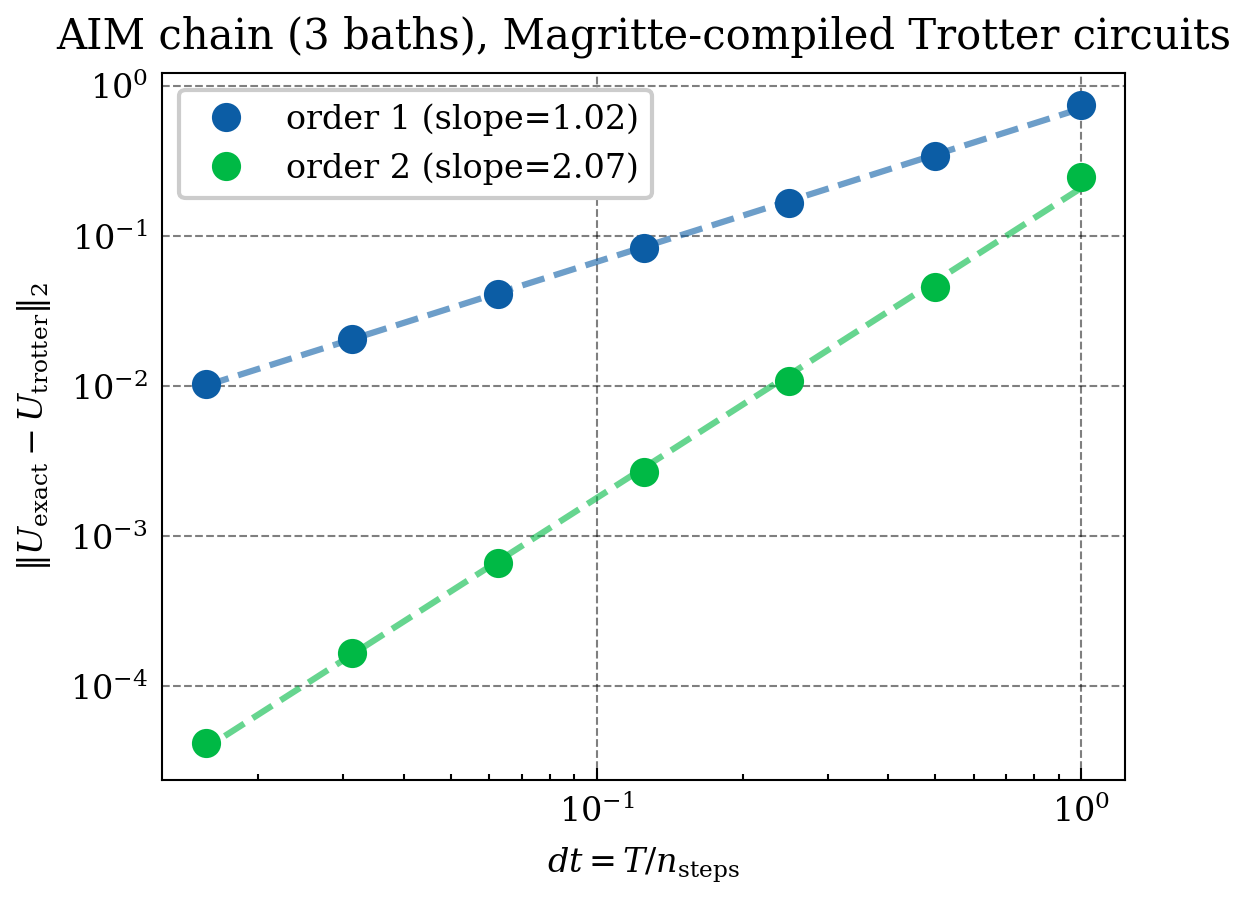

In [9]:
fig, ax = plt.subplots(figsize=(4, 3.2))
colors = {1: "C0", 2: "C1"}

for order in (1, 2):
    rows = [r for r in results if r[1] == order]
    dts = np.array([r[2] for r in rows])
    errs = np.array([r[3] for r in rows])
    slope, intercept = np.polyfit(np.log(dts), np.log(errs), 1)
    print(f"order={order}: fitted slope = {slope:.3f} (expect ~{order})")

    ax.loglog(dts, errs, "o", color=colors[order], label=f"order {order} (slope={slope:.2f})")
    fit_line = np.exp(intercept) * dts**slope
    ax.loglog(dts, fit_line, "--", color=colors[order], alpha=0.6)

ax.set_xlabel(r"$dt = T / n_{\rm steps}$")
ax.set_ylabel(r"$\Vert U_{\rm exact} - U_{\rm trotter} \Vert_2$")

ax.set_title("AIM chain (3 baths), Magritte-compiled Trotter circuits")
ax.legend()
fig.tight_layout()

## Summary

- `from_magritte_json` correctly parses every gate in this export (`RZZ`, `Rz`, `XY`,
  `GLOBAL_PHASE`) -- the full set task22's proposal predicted `AndersonImpurity.chain` would
  produce.
- **Each exported file is a single Trotter step**, not the fully repeated circuit -- apply it
  `n_steps` times to reach `total_time`. (Caught by noticing the gate count doesn't grow with
  `n_steps` in the raw files -- worth flagging back if the export format changes.)
- The converted circuits' full propagators converge to the independently-built exact
  $e^{-iHT}$ with the textbook first-/second-order Trotter scaling in operator norm -- the
  first real, non-hand-constructed confirmation that the Magritte -> Qaravan gate translation
  (angle-halving, mode-order convention) is physically correct, not just internally consistent.
- Not yet covered by this export: the star geometry, and any compiler/gateset other than
  `tds_unstructured_modes_no_swap_network` / `ALL`.